# From rays to waves: the focus of a lithography projection lens

A ray trace tells where the light of a lens goes, a wave propagator tells
what it looks like when it gets there. This notebook combines the two for
J. B. Caldwell's all fused silica KrF projection lens
(`raytrace.caldwell_krf_lens()`, 248.3 nm, image side NA 0.56, 4x, see
notebook 19) and looks at the light around the wafer plane:

1. **lens to focus**: the traced exit pupil gives the field in the image
   plane (`System.psf()`), the angular spectrum
   (`propagators.rayleigh_sommerfeld_I_TF()`) carries it through focus.
   The xz sections show the converging cone, the focus and the diverging
   cone, with the traced rays on top; a check of the axial intensity
   against the analytical depth of focus,
2. **caustics of a misaligned lens**: one element shifted along the axis
   (spherical aberration) and one decentred (coma). The geometrical
   caustic of a dense ray bundle next to the wave picture, and the
   through focus spots,
3. **axial colour**: the single glass lens moves its focus by about
   0.25 µm per pm of wavelength. A false colour stack of wavelengths and
   the focus of lasers of different bandwidth,
4. the same picture for an **ArF water immersion lens at NA 1.35**
   (`raytrace.zeiss_arfi_lens()`), vectorially: the focal field from
   `System.vectorial_focus()`, propagated with
   `propagators.vectorial_rayleigh_sommerfeld_TF()`.

Why not propagate the wave through the lens itself? The beam inside is up
to 200 mm wide, at 248 nm a grid would need about 10⁶ samples across.
Rays carry the light through the glass, waves take over at the exit
pupil. The hand-off is accurate because the focal region (tens of µm) is
tiny compared to the beam and the distances in the lens (millimetres):
there, each ray is a plane wave of the focal field.

Lengths are in mm as in the lens prescriptions; the plots show µm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from scipy.interpolate import CloughTocher2DInterpolator

from pyoptics.propagators import rayleigh_sommerfeld_I_TF_planes, vectorial_rayleigh_sommerfeld_TF
from pyoptics.raytrace import caldwell_krf_lens, zeiss_arfi_lens, WATER_ARF

plt.style.use("dark_background")
plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 10,
                     "axes.titlesize": 10})

um = 1e-3  # mm
lens = caldwell_krf_lens()
wl = lens.wavelength
NA = lens.pupil(0.0, 48).NA
print("wavelength {:.1f} nm, NA {:.3f}, magnification {:.3f}".format(
    wl*1e6, NA, lens.paraxial().magnification))

wavelength 248.3 nm, NA 0.560, magnification -0.250


## 1. Lens to focus

`System.psf()` traces a grid of rays through the lens, interpolates their
optical path differences on the exit pupil and Fourier transforms the
pupil into the amplitude in the image plane, centred on the chief ray.
That field is the starting plane of an angular spectrum propagation: every
plane wave of its spectrum gets the phase $\exp(i k_z z)$, which is exact
(no paraxial approximation). The grid spacing of 180 nm resolves the
amplitude (the pupil reaches up to NA/λ = 2.3 µm⁻¹, Nyquist needs
dx < 220 nm), the 72 µm window holds the cone up to ±20 µm from focus.

`section()` collects the xz and yz sections through the chief ray. The
traced rays are straight lines behind the last lens; `image_rays()`
returns their positions and slopes in the image plane relative to the
chief ray.

In [2]:
def grid(L, N):
    # x = 0 at index N//2, as pyoptics.fft expects
    return L/N*(np.arange(N) - N//2)


def section(system, x, zs, field=0.0, N=96, n=1.0):
    # xz and yz sections (through the chief ray) of the field around the image plane
    E0 = system.psf(x, x, field=field, N=N)
    c = len(x)//2
    E = rayleigh_sommerfeld_I_TF_planes(E0, x, x, zs, system.wavelength, n=n)[0]  # (z, y, x)
    return E[:, c, :], E[:, :, c]


def image_rays(system, field, px, py):
    # image plane positions relative to the chief ray and slopes dx/dz, dy/dz
    b = system.trace_pupil(field, px, py)
    chief = system.trace_pupil(field, 0.0, 0.0)
    P, d = system.to_image_frame(b.points[-1], b.directions[-1])
    P = P - system.to_image_frame(chief.points[-1])[0]
    ok = b.valid
    return P[ok, :2], d[ok, :2]/d[ok, 2:]


def show(ax, S, x, zs, dB=40, label="x"):
    I = np.abs(S)**2
    im = ax.imshow(10*np.log10(I.T/I.max() + 1e-12), extent=[zs[0]/um, zs[-1]/um, x[0]/um, x[-1]/um],
                   aspect="auto", cmap="inferno", vmin=-dB, vmax=0, interpolation="bicubic")
    ax.set_xlabel("z (µm)")
    ax.set_ylabel(label + " (µm)")
    return im


def draw_rays(ax, P, t, zs, axis=0, **kw):
    zz = np.array([zs[0], zs[-1]])
    for p, s in zip(P[:, axis], t[:, axis]):
        ax.plot(zz/um, (p + s*zz)/um, **{"color": "w", "lw": 0.3, "alpha": 0.4, **kw})


x = grid(72*um, 400)
zs = np.linspace(-15*um, 15*um, 241)
fan = np.linspace(-1, 1, 17)

The layout (as in notebook 19) and the light at the wafer for the centre
and the edge of the 23.4 mm image field (object heights 0 and 46.8 mm).
The colour scale is logarithmic over 40 dB. In the cone the rings of the
defocused Airy pattern appear as streaks, on the axis the dark spots are
the axial zeros of the defocused spot (Fresnel zones of the pupil). At the
edge of the field the yz section (tangential, the field is in y) is
slightly asymmetric: the residual coma and astigmatism of the design.

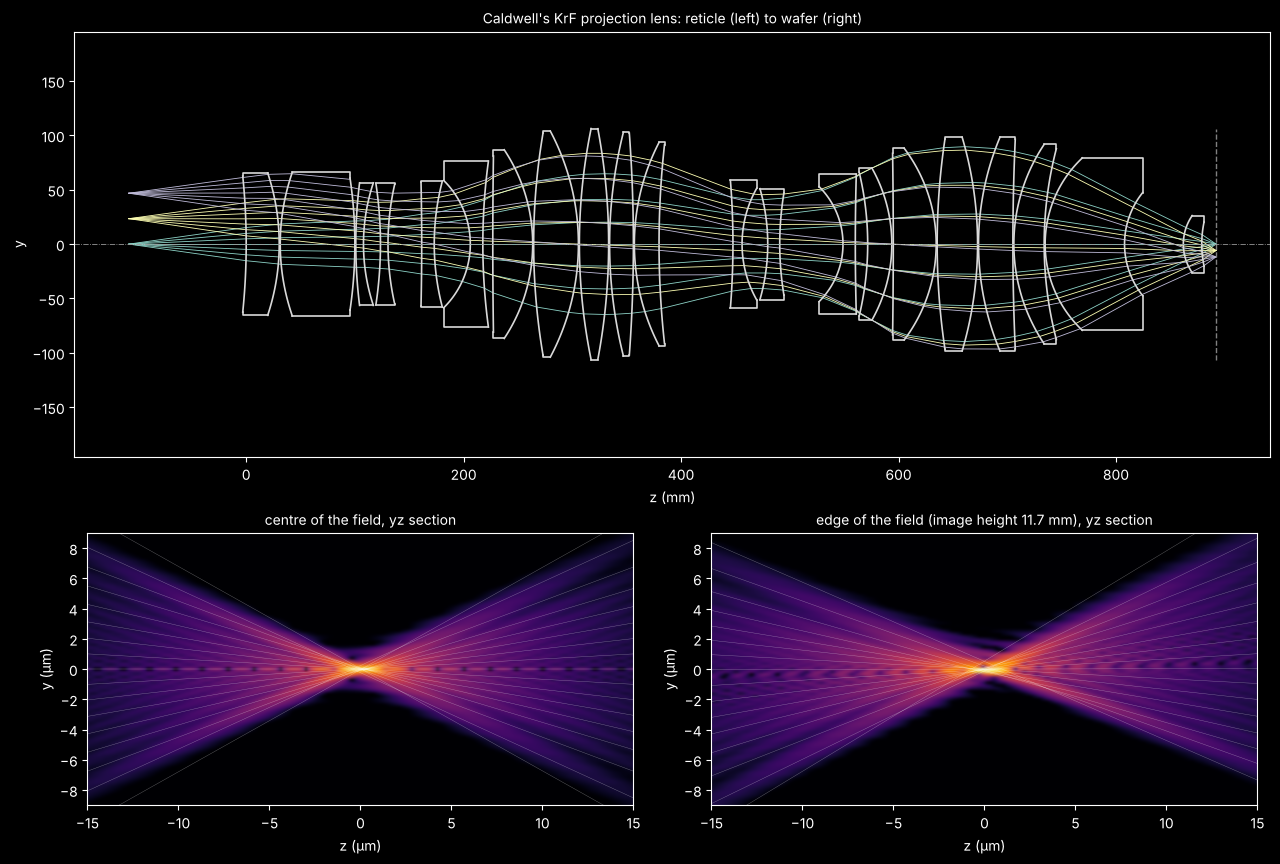

In [3]:
fig = plt.figure(figsize=(13, 8.5))
ax0 = fig.add_axes([0.05, 0.47, 0.92, 0.5])
lens.draw(ax=ax0, fields=[0.0, 23.4, 46.8], n_rays=7, lw=0.6)
for line in ax0.lines + ax0.patches:
    if line.get_color() in ("k", "black", (0.0, 0.0, 0.0, 1.0)):
        line.set_color("0.85")
ax0.set_title("Caldwell's KrF projection lens: reticle (left) to wafer (right)")
ax0.set_xlabel("z (mm)")

for k, (f, name) in enumerate([(0.0, "centre of the field"), (46.8, "edge of the field (image height 11.7 mm)")]):
    S_x, S_y = section(lens, x, zs, field=f)
    ax = fig.add_axes([0.06 + 0.48*k, 0.06, 0.42, 0.32])
    show(ax, S_y, x, zs, label="y")
    P, t = image_rays(lens, f, 0*fan, fan)
    draw_rays(ax, P, t, zs, axis=1)
    ax.set_ylim(-9, 9)
    ax.set_title(name + ", yz section")
    if k == 0:
        S_axis = S_x

### Check: depth of focus

On axis the scalar focus of a uniformly filled pupil (uniform in the
transverse wave vector, as `psf()` assumes) is the sum of plane waves
$$U(0, 0, z) \propto \int_0^{k\,\mathrm{NA}} e^{i k_z z}\, k_t\, dk_t
  = \int_{k\cos\alpha}^{k} e^{i k_z z}\, k_z\, dk_z,$$
with $\sin\alpha$ = NA. In the paraxial limit its intensity is
$\mathrm{sinc}^2$ with a full width at half maximum of
$1.77\,\lambda/\mathrm{NA}^2$. At NA 0.56 the exact focus is about 10 %
shorter; the propagated field of the real lens follows the exact curve.

1.77 wl/NA**2 = 1.40 µm


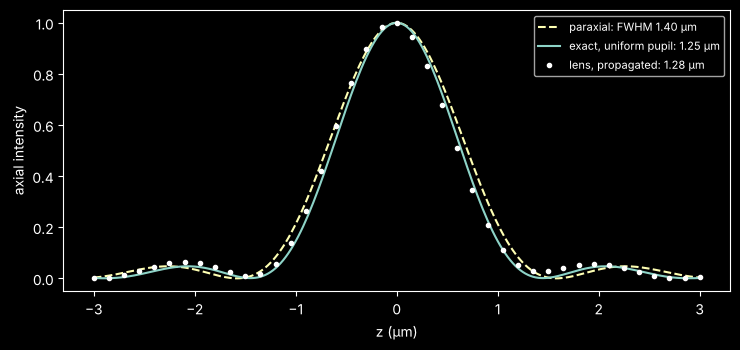

In [4]:
zf = np.linspace(-3*um, 3*um, 241)
S_f = section(lens, x, zf)[0][:, len(x)//2]
I_lens = np.abs(S_f)**2/np.max(np.abs(S_f)**2)

k = 2*np.pi/wl
kz = np.linspace(k*np.sqrt(1 - NA**2), k, 2001)
U = np.trapezoid(kz*np.exp(1j*np.outer(zf, kz)), kz, axis=1)
I_exact = np.abs(U)**2/np.max(np.abs(U)**2)
u = k*NA**2*zf/4
I_parax = np.sinc(u/np.pi)**2


def fwhm(z, I):
    above = z[I >= 0.5*I.max()]
    return above[-1] - above[0]


fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(zf/um, I_parax, "C1--", label="paraxial: FWHM {:.2f} µm".format(fwhm(zf, I_parax)/um))
ax.plot(zf/um, I_exact, "C0", label="exact, uniform pupil: {:.2f} µm".format(fwhm(zf, I_exact)/um))
ax.plot(zf[::6]/um, I_lens[::6], "wo", ms=3, label="lens, propagated: {:.2f} µm".format(fwhm(zf, I_lens)/um))
ax.set_xlabel("z (µm)"), ax.set_ylabel("axial intensity")
ax.legend(fontsize=8)
plt.tight_layout()
print("1.77 wl/NA**2 = {:.2f} µm".format(1.77*wl/NA**2/um))

## 2. Caustics of a misaligned lens

Two misalignments of single elements, both large compared to real
tolerances so that the aberration shows:

- **element 16** (surfaces 31 and 32, behind the stop) shifted by 0.12 mm
  along the axis. This mostly defocuses; with the image plane moved to the
  new paraxial focus, about one wave of spherical aberration (Z9) is left,
- **element 15** (surfaces 29 and 30, carrying the stop) decentred by
  50 µm in x: coma (Z7) on axis.

In [5]:
def decentred(system, i, dx):
    other = system.copy()
    for j in (i, i + 1):
        other.surfaces[j].decenter = (dx, 0.0)
    return other


spherical = lens.with_axial_shift(30, 31, 0.12).at_paraxial_focus()
coma = decentred(lens, 28, 0.05)
for name, s in (("nominal", lens), ("element 16 shifted", spherical), ("element 15 decentred", coma)):
    c = s.zernike(0.0, 16, 32)
    print("{:22s} Z4 {:+.2f}  Z7 {:+.2f}  Z9 {:+.2f} waves,  Strehl {:.2f}".format(
        name, c[3], c[6], c[8], s.strehl(0.0, 48)))

nominal                Z4 -0.01  Z7 +0.00  Z9 -0.06 waves,  Strehl 0.97
element 16 shifted     Z4 -2.72  Z7 +0.00  Z9 -1.19 waves,  Strehl 0.03


element 15 decentred   Z4 -0.01  Z7 -1.32  Z9 -0.06 waves,  Strehl 0.00


### Rays and waves

Geometrical optics predicts the intensity by the density of rays. A dense
ray bundle is cheap when the ray data are interpolated: `ray_map()`
traces 61 × 61 rays across the pupil and interpolates the image plane
positions and slopes (Clough–Tocher, smooth in the pupil coordinates) for
half a million random pupil points. The histogram of the rays within
±50 nm of the xz plane is the geometrical intensity of the section. It shows the
**caustic**, the envelope of the rays where geometrical optics predicts
infinite intensity: the cusp of the spherical aberration on the axis, the
curved line of the coma. The wave field (right) smooths the caustic into
fringes, in particular on the bright side of the caustic, where two rays
cross every point and interfere.

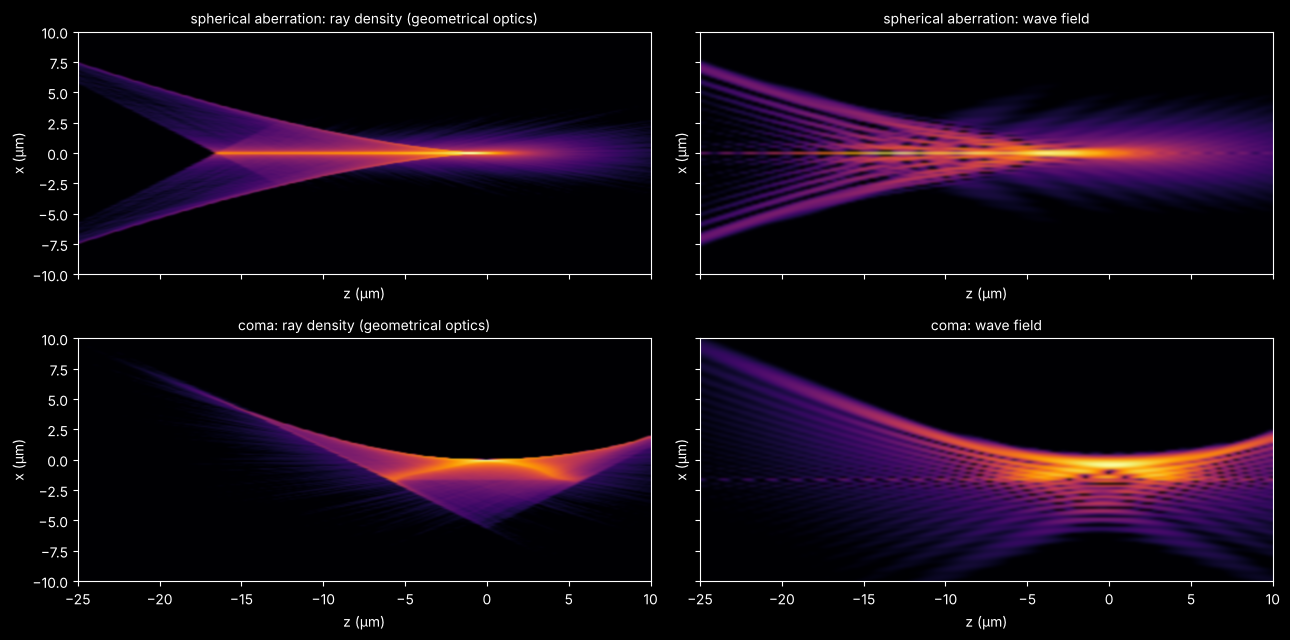

In [6]:
def ray_map(system, field=0.0, n=61):
    p = np.linspace(-1, 1, n)
    PX, PY = np.meshgrid(p, p)
    inside = PX**2 + PY**2 <= 1
    phi = np.linspace(0, 2*np.pi, 4*n, endpoint=False)
    px, py = np.r_[PX[inside], np.cos(phi)], np.r_[PY[inside], np.sin(phi)]
    b = system.trace_pupil(field, px, py)
    chief = system.trace_pupil(field, 0.0, 0.0)
    P, d = system.to_image_frame(b.points[-1], b.directions[-1])
    P = P - system.to_image_frame(chief.points[-1])[0]
    ok = b.valid
    values = np.column_stack([P[ok, :2], d[ok, :2]/d[ok, 2:]])
    return CloughTocher2DInterpolator(np.column_stack([px[ok], py[ok]]), values)


def ray_density(system, x_edges, zs, field=0.0, n_rays=5*10**5, slab=0.05*um, seed=1):
    rng = np.random.default_rng(seed)
    r, phi = np.sqrt(rng.random(n_rays)), 2*np.pi*rng.random(n_rays)  # uniform over the pupil
    v = ray_map(system, field)(r*np.cos(phi), r*np.sin(phi))
    v = v[np.isfinite(v).all(axis=1)]
    H = []
    for z in zs:
        X, Y = v[:, 0] + v[:, 2]*z, v[:, 1] + v[:, 3]*z
        H.append(np.histogram(X[np.abs(Y) < slab], x_edges)[0])
    return np.array(H, dtype=float)


zc = np.linspace(-25*um, 10*um, 176)
x_edges = np.linspace(-10*um, 10*um, 201)
x_c = 0.5*(x_edges[1:] + x_edges[:-1])
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
sections = {}
for row, (name, s) in zip(axes, (("spherical aberration", spherical), ("coma", coma))):
    H = ray_density(s, x_edges, zc)
    show(row[0], np.sqrt(H), x_c, zc, dB=30)
    row[0].set_title(name + ": ray density (geometrical optics)")
    sections[name] = section(s, x, zc)[0]
    show(row[1], sections[name], x, zc, dB=30)
    row[1].set_title(name + ": wave field")
for ax in axes.flat:
    ax.set_ylim(-10, 10)
plt.tight_layout()

### Through focus

The spots at seven planes, square root of the intensity (each row scaled
to its brightest plane). Spherical aberration makes the defocused spots
different on the two sides of focus: sharp rings on one side, a diffuse
blur on the other, the classic star test. Coma gives the comet shaped
spot. Its tail points the same way on both sides of focus; defocus
only opens the flare into wider arcs.

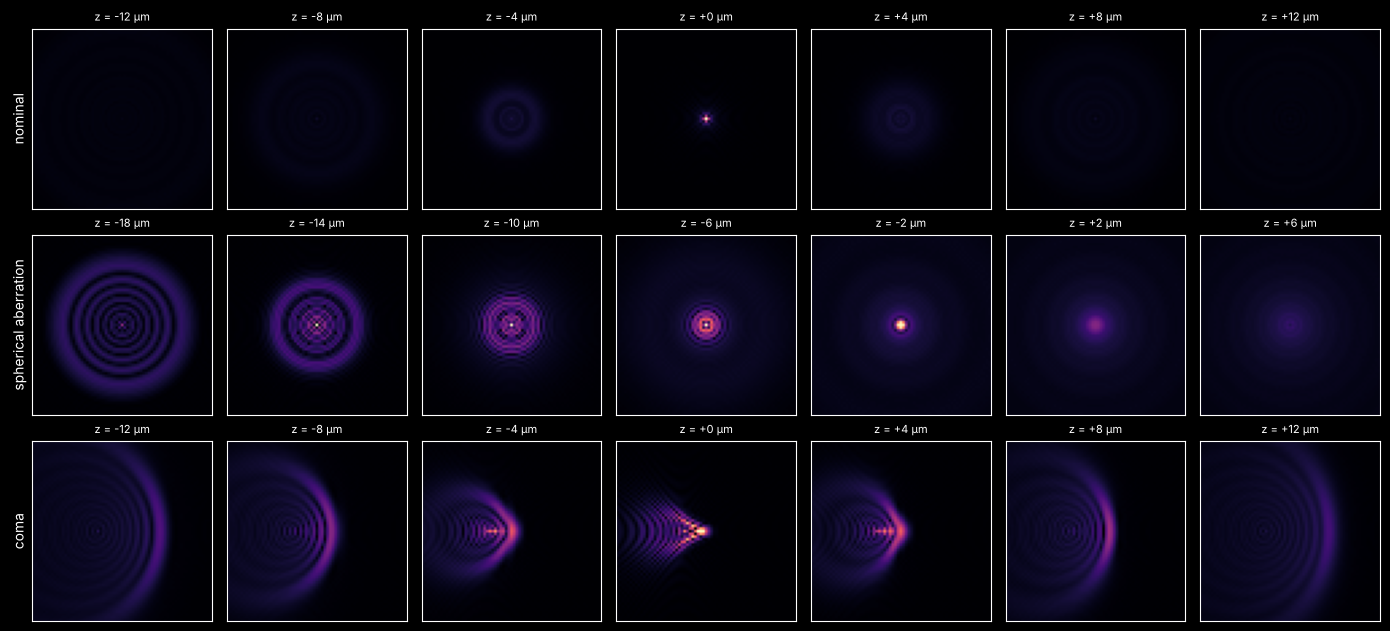

In [7]:
def planes(system, zs, field=0.0, N=96):
    E0 = system.psf(x, x, field=field, N=N)
    return rayleigh_sommerfeld_I_TF_planes(E0, x, x, zs, wl)[0]


zp = np.linspace(-12*um, 12*um, 7)
rows = (("nominal", lens, 0.0), ("spherical aberration", spherical, -6*um), ("coma", coma, 0.0))
fig, axes = plt.subplots(3, 7, figsize=(14, 6.4))
for row, (name, s, z0) in zip(axes, rows):
    I = np.abs(planes(s, zp + z0))**2
    for ax, z, I_z in zip(row, zp + z0, I):
        ax.imshow(np.sqrt(I_z/I.max()), extent=[x[0]/um, x[-1]/um]*2, cmap="magma", vmax=0.8)
        ax.set_xlim(-6, 6), ax.set_ylim(-6, 6)
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_title("z = {:+.0f} µm".format(z/um), fontsize=8)
    row[0].set_ylabel(name)
plt.tight_layout()

## 3. Axial colour

A lens of a single glass cannot be colour corrected. Nine wavelengths from
−40 pm to +40 pm around 248.3 nm, each with the lens retraced at that
wavelength (`System.with_wavelength()`, image plane fixed), coloured from
blue (short) to red (long) and added. The colours are false: all of this
is deep ultraviolet. Shorter wavelengths see a higher index and focus
closer to the lens.

axial colour 0.242 µm/pm


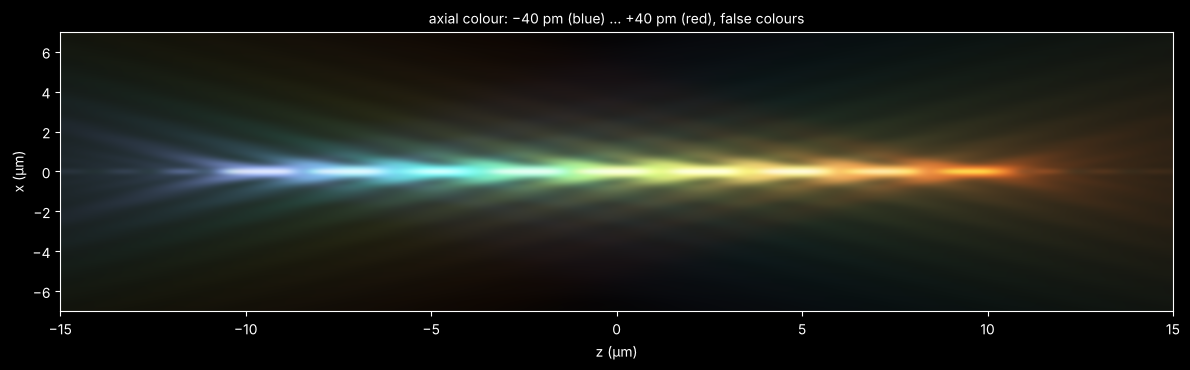

In [8]:
dls = np.linspace(-40e-9, 40e-9, 9)  # pm in mm
cmap = colormaps["turbo"]
rgb = 0.0
peaks = []
for i, dl in enumerate(dls):
    S = section(lens.with_wavelength(wl + dl), x, zs[::2])[0]
    I = np.abs(S.T)**2
    peaks.append(zs[::2][np.argmax(I[len(x)//2])])
    rgb = rgb + I[..., None]*np.array(cmap(0.1 + 0.8*i/(len(dls) - 1))[:3])
rgb = np.clip(rgb/np.percentile(rgb, 99.8), 0, 1)**0.5

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.imshow(rgb, extent=[zs[0]/um, zs[::2][-1]/um, x[0]/um, x[-1]/um], aspect="auto", interpolation="bicubic")
ax.set_ylim(-7, 7)
ax.set_xlabel("z (µm)"), ax.set_ylabel("x (µm)")
ax.set_title("axial colour: −40 pm (blue) ... +40 pm (red), false colours")
plt.tight_layout()
slope = np.polyfit(dls*1e9, peaks, 1)[0]  # mm per pm
print("axial colour {:.3f} µm/pm".format(slope/um))

Over a few ten pm the colour is a pure focus shift: the focus of every
wavelength is the nominal focus moved along z. The focus of a laser with
a spectrum $S(\Delta\lambda)$ is therefore the nominal intensity convolved
along $z$ with the spectrum mapped to $z$ by the axial colour. Lithography
KrF lasers are line narrowed to well below 1 pm FWHM, a free running KrF
laser emits about 300 pm. Below, Lorentzian spectra (the line shape of a
narrowed laser) of increasing width, peak intensity relative to a single
wavelength.

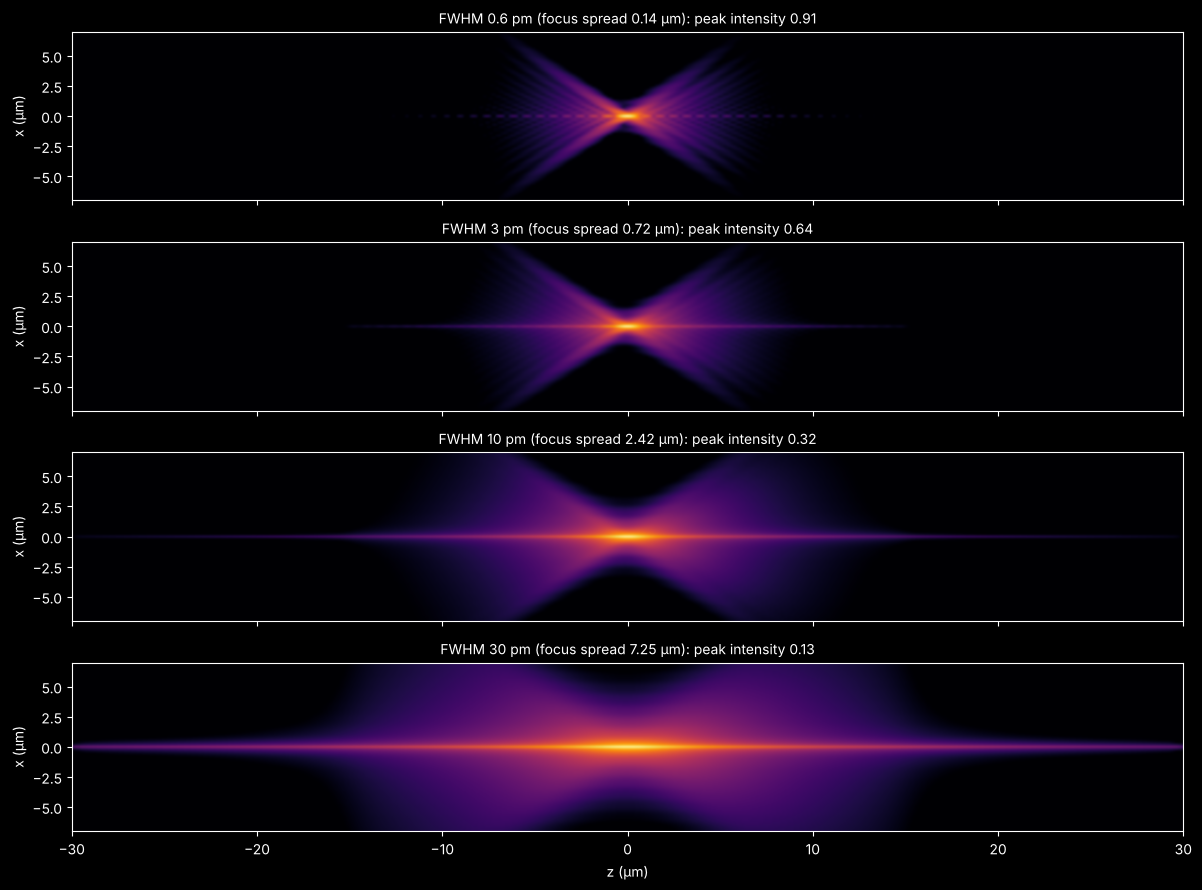

In [9]:
zw = np.linspace(-30*um, 30*um, 401)
I0 = np.abs(section(lens, x, zw)[0].T)**2
dz = zw[1] - zw[0]


def lorentzian(fwhm, n):
    # spectrum of the given FWHM (pm) mapped to the z steps -n ... n, normalized
    j = np.arange(-n, n + 1)
    gamma = 0.5*fwhm*slope/dz
    L = 1/(1 + (j/gamma)**2) if gamma > 0.05 else (j == 0).astype(float)
    return L/L.sum()


widths = [0.6, 3.0, 10.0, 30.0]  # FWHM in pm
fig, axes = plt.subplots(len(widths), 1, figsize=(12, 9), sharex=True)
for ax, w in zip(axes, widths):
    kernel = lorentzian(w, len(zw))
    I_w = np.array([np.convolve(row, kernel, mode="same") for row in I0])
    show(ax, np.sqrt(I_w).T, x, zw, dB=35)
    ax.set_ylim(-7, 7)
    ax.set_title("FWHM {:g} pm (focus spread {:.2f} µm): peak intensity {:.2f}".format(
        w, w*slope/um, I_w.max()/I0.max()))
    ax.set_xlabel("")
axes[-1].set_xlabel("z (µm)")
plt.tight_layout()

For the 300 pm of a free running laser the focus spreads over 70 µm,
beyond the window. The axial intensity of the aberration free pupil
(section 1) over ±400 µm, convolved with the spectrum, gives the peak.
Even at 0.6 pm FWHM the far tails of the Lorentzian cost almost 10 % of
it, which is why laser specifications also give the E95 bandwidth (the
width that holds 95 % of the energy):

In [10]:
z_long = np.arange(-400*um, 400*um, dz)
U = np.trapezoid(kz*np.exp(1j*np.outer(z_long, kz)), kz, axis=1)
I_axis = np.abs(U)**2/np.max(np.abs(U)**2)
for w in (0.6, 30.0, 300.0):
    print("FWHM {:5.1f} pm: peak intensity {:.3f}".format(
        w, np.convolve(I_axis, lorentzian(w, len(z_long)), mode="same").max()))

FWHM   0.6 pm: peak intensity 0.913
FWHM  30.0 pm: peak intensity 0.120
FWHM 300.0 pm: peak intensity 0.013


## 4. NA 1.35: an ArF immersion lens

The dioptric water immersion lens of Zeiss' US patent 7,187,503
(`raytrace.zeiss_arfi_lens()`, 193.4 nm, 8x, NA 1.35 in water,
n = 1.437). At this NA the scalar picture is not enough: the field of a
linearly polarized pupil has a strong longitudinal component $E_z$.
`System.vectorial_focus()` sums the polarization traced rays as plane
waves into the vectorial field of the image plane,
`vectorial_rayleigh_sommerfeld_TF()` propagates it in water (E_x and E_y
by the angular spectrum, E_z from div E = 0). Both lenses on the same
scale: the cone of the immersion lens opens to ±70° in water, its focus
is about three times narrower and seven times shorter.

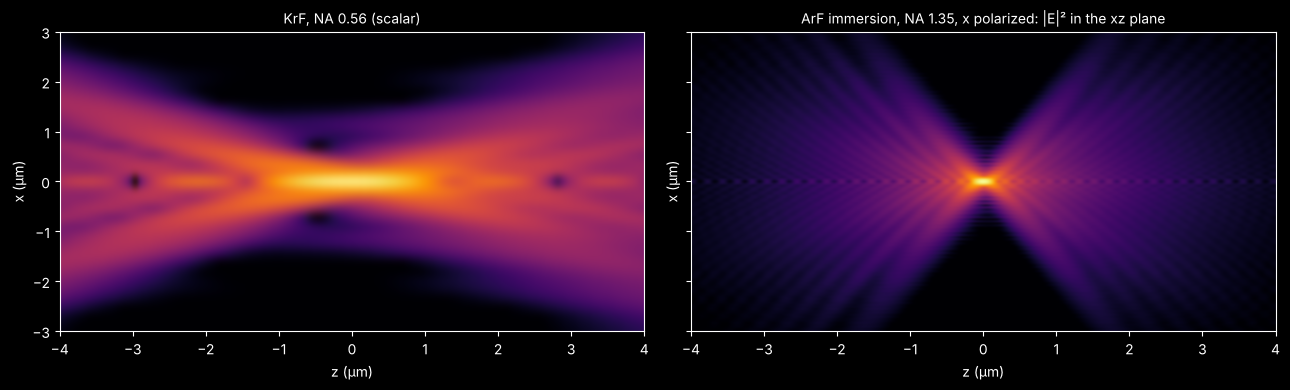

In [11]:
arfi = zeiss_arfi_lens()
wl_a = arfi.wavelength
xa = grid(16*um, 400)
za = np.linspace(-4*um, 4*um, 201)
E0 = arfi.vectorial_focus(xa, xa, E_in=(1.0, 0.0), N=48)  # x polarized
c = len(xa)//2
E_x, E_y = [], []  # sections xz (along the polarization) and yz
for z in za:
    E = vectorial_rayleigh_sommerfeld_TF(E0, xa, xa, z, wl_a, n=WATER_ARF)[0]
    E_x.append(E[c, :, :])
    E_y.append(E[:, c, :])
E_x, E_y = np.array(E_x), np.array(E_y)

S_k = section(lens, x, za)[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
show(axes[0], S_k, x, za)
axes[0].set_title("KrF, NA 0.56 (scalar)")
show(axes[1], np.sqrt(np.sum(np.abs(E_x)**2, axis=-1)), xa, za)
axes[1].set_title("ArF immersion, NA 1.35, x polarized: |E|² in the xz plane")
axes[0].set_ylim(-3, 3)
plt.tight_layout()

The components in the plane of the polarization (xz) and across it (yz),
each scaled to its maximum (in the titles, relative to the peak of
$|E_x|^2$). $E_z$ is zero on the axis and has two lobes along the
polarization, with almost a quarter of the peak intensity of $E_x$; it
widens the focus along x. In the yz plane $E_z$ vanishes by
symmetry, and the cross polarized $E_y$ is weak everywhere.

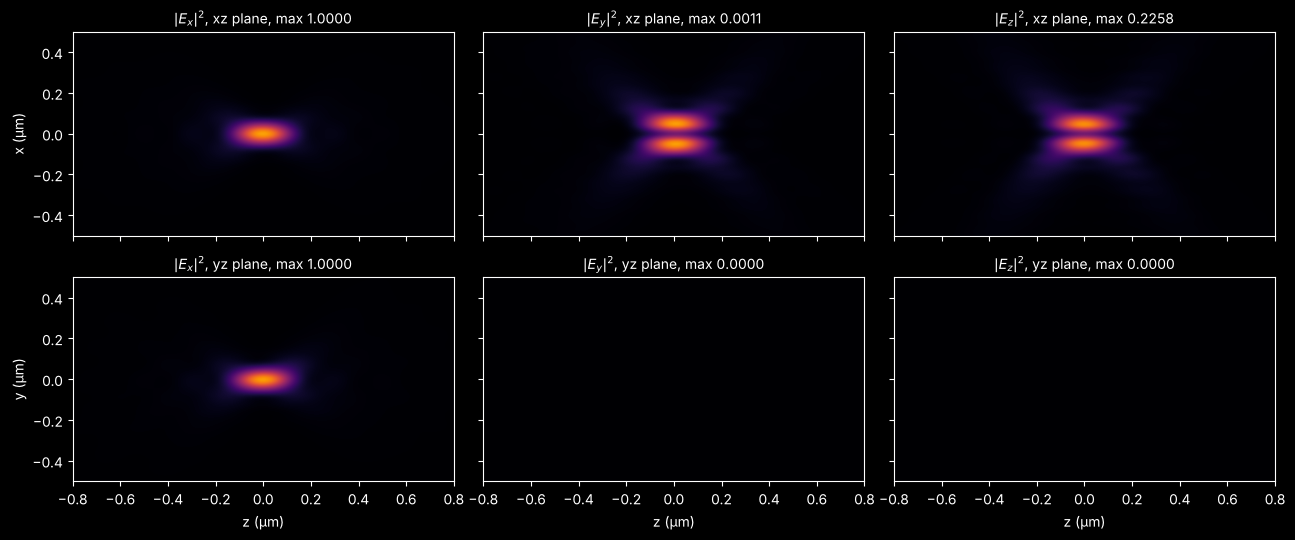

In [12]:
I_max = np.max(np.abs(E_x[..., 0])**2)
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True, sharey=True)
for row, (E, plane) in zip(axes, ((E_x, "x"), (E_y, "y"))):
    for ax, j, comp in zip(row, range(3), "xyz"):
        I = np.abs(E[..., j])**2
        ax.imshow(I.T/max(I.max(), 1e-6*I_max), extent=[za[0]/um, za[-1]/um, xa[0]/um, xa[-1]/um],
                  aspect="auto", cmap="inferno", vmin=0, vmax=1, interpolation="bicubic")
        ax.set_title("$|E_{}|^2$, {}z plane, max {:.4f}".format(comp, plane, I.max()/I_max))
        ax.set_xlim(-0.8, 0.8), ax.set_ylim(-0.5, 0.5)
    row[0].set_ylabel(plane + " (µm)")
for ax in axes[1]:
    ax.set_xlabel("z (µm)")
plt.tight_layout()

## Summary

- The traced exit pupil (`System.psf()`, `System.vectorial_focus()`) is the
  natural starting point for wave propagation: the angular spectrum
  (`rayleigh_sommerfeld_I_TF()`) carries the focal field forwards and
  backwards through focus, exact at any NA. Since this notebook, the
  angular spectrum propagators drop evanescent waves for negative z, which
  would otherwise amplify the roundoff of the field exponentially.
- The axial intensity of the Caldwell lens agrees with the non-paraxial
  depth of focus of a uniformly filled pupil; the paraxial
  $1.77\,\lambda/\mathrm{NA}^2$ is 10 % too long at NA 0.56.
- Ray density from an interpolated ray map shows the geometrical caustics
  of a misaligned lens; the wave field smooths them into fringes.
- The axial colour of a single glass lens is a focus shift of 0.25 µm/pm,
  so the laser spectrum blurs the focus along z: a line narrowed laser
  leaves it unchanged, a free running one smears it over tens of µm.
- At NA 1.35 in water the focus is a vector field with a strong
  longitudinal component along the polarization.